# Часть 1. Очистка данных и анализ

Датасет: Predict Students' Dropout and Academic Success (Kaggle). Каждая строка - один студент португальского вуза: данные при поступлении, оценки за 1 и 2 семестр и итог (Target: Dropout, Enrolled, Graduate).

Задача: предсказать, отчислится студент или нет.

Что делаю в ноутбуке:
1. Чищу данные: дубликаты, пропуски, логические ошибки.
2. Беру 25% данных для анализа, остальные 75% оставляю для проверки гипотез.
3. На 25% строю графики, считаю среднее и медиану.
4. Формулирую гипотезы.
5. Проверяю их на 75%.
6. Вывод.

## 1. Загрузка данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

In [2]:
# encoding="utf-8-sig" убирает маркер BOM, иначе первый столбец называется "\ufeffMarital status".
df = pd.read_csv("dataset.csv", encoding="utf-8-sig")
print(df.shape)
df.head()

(4424, 35)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,10,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,4,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,10,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,4,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,10,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 2. Очистка данных

### 2.1 Дубликаты

Если строка повторяется полностью, значит один и тот же студент записан два раза. Такие строки надо удалять, иначе он будет считаться дважды во всех средних.

In [3]:
dups = df.duplicated().sum()
print("Полных дубликатов:", dups)
if dups:
    df = df.drop_duplicates()
print("Размер после удаления дубликатов:", df.shape)

Полных дубликатов: 0
Размер после удаления дубликатов: (4424, 35)


### 2.2 Пропуски

Проверяю обычные пропуски (NaN) и пустые строки в текстовых столбцах, потому что isna() их не находит.

Если бы пропуски были, я бы заполнил числовые столбцы медианой (она меньше зависит от выбросов, чем среднее), а строки без Target удалил бы.

In [4]:
print("Явных пропусков (NaN):", df.isna().sum().sum())
text_cols = df.select_dtypes(exclude="number").columns
print("Скрытых пропусков (пустые строки / пробелы):",
      df[text_cols].apply(lambda s: s.str.strip().eq("")).sum().sum())

Явных пропусков (NaN): 0
Скрытых пропусков (пустые строки / пробелы): 0


### 2.3 Логические ошибки

Даже если нет пропусков и дубликатов, значения могут противоречить друг другу. Проверяю такие правила:
- сдано предметов (approved) не больше, чем записано (enrolled);
- сдано не больше, чем было попыток сдачи (evaluations);
- предметов без оценки (without evaluations) не больше, чем записано;
- если сдан хотя бы один предмет (approved > 0), то средний балл (grade) больше 0, а если не сдано ни одного, то балл равен 0;
- балл от 0 до 20 (в Португалии 20-балльная шкала);
- International = 1 только у тех, кто не из Португалии (Nacionality не равно 1);
- возраст при поступлении не меньше 17;
- у выпускника не может быть 0 предметов за оба семестра.

In [5]:
checks = {}
for s in ["1st", "2nd"]:
    e  = df[f"Curricular units {s} sem (enrolled)"]
    a  = df[f"Curricular units {s} sem (approved)"]
    ev = df[f"Curricular units {s} sem (evaluations)"]
    g  = df[f"Curricular units {s} sem (grade)"]
    w  = df[f"Curricular units {s} sem (without evaluations)"]
    checks[f"{s}: approved > enrolled"]        = (a > e).sum()
    checks[f"{s}: approved > evaluations"]     = (a > ev).sum()
    checks[f"{s}: without_eval > enrolled"]    = (w > e).sum()
    checks[f"{s}: grade>0 при approved==0"]    = ((g > 0) & (a == 0)).sum()
    checks[f"{s}: grade==0 при approved>0"]    = ((g == 0) & (a > 0)).sum()
    checks[f"{s}: grade вне [0, 20]"]          = ((g < 0) | (g > 20)).sum()

checks["International=1, но Nacionality=Португалия"] = ((df["International"] == 1) & (df["Nacionality"] == 1)).sum()
checks["International=0, но Nacionality не Португалия"] = ((df["International"] == 0) & (df["Nacionality"] != 1)).sum()
checks["Age < 17"] = (df["Age at enrollment"] < 17).sum()

no_units = (df["Curricular units 1st sem (enrolled)"] == 0) & (df["Curricular units 2nd sem (enrolled)"] == 0)
checks["0 дисциплин за оба семестра (всего)"] = no_units.sum()
checks["  из них Graduate"] = (no_units & (df["Target"] == "Graduate")).sum()

pd.Series(checks, name="число нарушений").to_frame()

,число нарушений
1st: approved > enrolled,0
1st: approved > evaluations,0
1st: without_eval > enrolled,0
1st: grade>0 при approved==0,0
1st: grade==0 при approved>0,0
"1st: grade вне [0, 20]",0
2nd: approved > enrolled,0
2nd: approved > evaluations,0
2nd: without_eval > enrolled,3
2nd: grade>0 при approved==0,0


Нашлось два типа ошибок.

1) 3 строки, где во 2 семестре предметов без оценки больше, чем записано. Так быть не может, скорее всего ошибка при выгрузке. Исправить не на что, строк мало, поэтому удаляю.

2) 180 студентов, у которых за оба семестра 0 предметов, и 75 из них при этом выпускники. Выпуститься без предметов нельзя. У остальных 105 тоже все 12 столбцов по предметам нулевые, то есть данных об их учёбе нет.

Удаляю все 180, а не только выпускников: если убрать строки только из одного класса, классы станут несопоставимыми. Все эти студенты с одного курса (Course = 2), это 180 из 215 его студентов. Похоже, по этому курсу просто не заполнили оценки. Это я уже находил в первой работе (Dataset_Overview, профиль качества). После удаления от курса 2 останется 35 человек, поэтому про этот курс выводы делать нельзя. Зато теперь 0 сданных предметов значит "не сдал", а не "нет данных".

In [6]:
bad_without_eval = df["Curricular units 2nd sem (without evaluations)"] > df["Curricular units 2nd sem (enrolled)"]
before = len(df)
df = df[~bad_without_eval & ~no_units].reset_index(drop=True)
print(f"Удалено строк: {before - len(df)}  →  осталось {len(df)}")

Удалено строк: 183  →  осталось 4241


### 2.4 Целевая переменная

Задача бинарная: 1 - Dropout, 0 - Enrolled или Graduate. Столбец Target тоже оставляю.

In [7]:
df["Dropout"] = (df["Target"] == "Dropout").astype(int)
print(df["Target"].value_counts(), "\n")
print("Доля отчислений, %:", round(df["Dropout"].mean() * 100, 1))

# Сохраняем очищенный датасет — его будет использовать ноутбук предобработки
df.to_csv("data_clean.csv", index=False)

Target
Graduate    2134
Dropout     1341
Enrolled     766
Name: count, dtype: int64 

Доля отчислений, %: 31.6


## 3. Делю данные на две части

Случайно беру 25% строк, на них смотрю графики и придумываю гипотезы. Остальные 75% откладываю и проверяю гипотезы только на них. Делю со stratify по Target, чтобы доли классов в обеих частях были одинаковые.

Зачем так: если придумать гипотезу на одних данных и проверить на них же, она почти точно подтвердится. Проверка на других данных честнее.

In [8]:
from sklearn.model_selection import train_test_split

explore, holdout = train_test_split(df, test_size=0.75, stratify=df["Target"], random_state=42)
print("Исследовательская часть:", explore.shape, " Отложенная часть:", holdout.shape)
print("\nДоля Dropout, %: исследование =", round(explore["Dropout"].mean()*100, 1),
      "| отложенная =", round(holdout["Dropout"].mean()*100, 1))

Исследовательская часть: (1060, 36)  Отложенная часть: (3181, 36)

Доля Dropout, %: исследование = 31.6 | отложенная = 31.6


## 4. Анализ 25% данных

Беру признаки, которые по смыслу могут влиять на отчисление:
- Age at enrollment - возраст при поступлении;
- Curricular units 1st sem (grade) - средний балл за 1 семестр;
- Debtor, Tuition fees up to date, Scholarship holder - деньги (долг, оплата, стипендия).

### 4.1 Среднее и медиана

Считаю и среднее, и медиану. Если они сильно отличаются, значит есть выбросы или перекос, которые тянут среднее.

In [9]:
num_feats = ["Age at enrollment", "Curricular units 1st sem (grade)", "Curricular units 1st sem (approved)"]
summary = explore[num_feats].agg(["mean", "median", "std", "min", "max"]).T.round(2)
summary

,mean,median,std,min,max
Age at enrollment,23.42,20.0,7.75,17.0,70.00
Curricular units 1st sem (grade),11.10,12.4,4.38,0.0,18.88
Curricular units 1st sem (approved),5.00,5.0,3.11,0.0,21.00


In [10]:
# То же, но отдельно по классам — видно ли различие между группами
explore.groupby("Target")[num_feats].agg(["mean", "median"]).round(2)

Age at enrollment        Curricular units 1st sem (grade)        Curricular units 1st sem (approved)       
                      mean median                             mean median                                mean median
Target                                                                                                              
Dropout              26.30   24.0                             7.75  11.00                                2.85    2.0
Enrolled             23.14   20.0                            11.42  11.83                                4.49    4.0
Graduate             21.71   19.0                            13.10  13.00                                6.54    6.0

Что видно:
- У возраста среднее (23) больше медианы (20), значит есть хвост из взрослых студентов. У отчисленных медиана возраста 24, у остальных 19-20.
- У балла наоборот, среднее меньше медианы, потому что есть нули (студенты, которые ничего не сдали). У отчисленных среднее 7.75, а медиана 11.

### 4.2 График 1. Возраст при поступлении

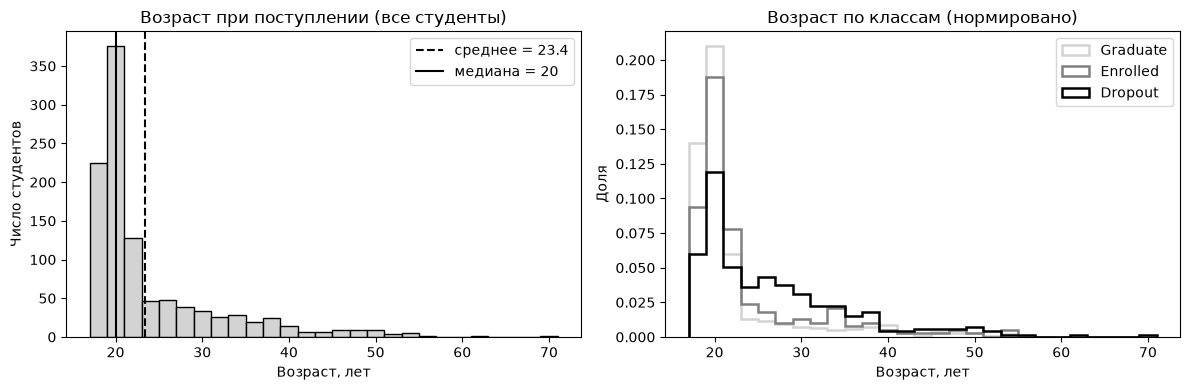

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(explore["Age at enrollment"], bins=range(17, 72, 2), edgecolor="black", color="lightgray")
ax[0].axvline(explore["Age at enrollment"].mean(), color="black", linestyle="--", label=f"среднее = {explore['Age at enrollment'].mean():.1f}")
ax[0].axvline(explore["Age at enrollment"].median(), color="black", linestyle="-", label=f"медиана = {explore['Age at enrollment'].median():.0f}")
ax[0].set_title("Возраст при поступлении (все студенты)")
ax[0].set_xlabel("Возраст, лет"); ax[0].set_ylabel("Число студентов"); ax[0].legend()

for t, c in [("Graduate", "lightgray"), ("Enrolled", "gray"), ("Dropout", "black")]:
    ax[1].hist(explore.loc[explore["Target"] == t, "Age at enrollment"], bins=range(17, 72, 2),
               histtype="step", linewidth=1.8, color=c, label=t, density=True)
ax[1].set_title("Возраст по классам (нормировано)")
ax[1].set_xlabel("Возраст, лет"); ax[1].set_ylabel("Доля"); ax[1].legend()
plt.tight_layout(); plt.show()

Большинство поступает в 18-20 лет, но есть студенты и за 60. На правом графике видно, что среди отчисленных больше тех, кому за 23. Из этого дальше сделаю гипотезу.

### 4.3 График 2. Средний балл за 1 семестр по классам

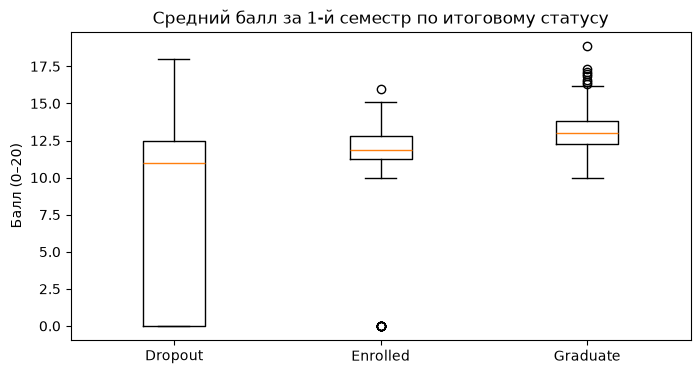

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
data = [explore.loc[explore["Target"] == t, "Curricular units 1st sem (grade)"] for t in ["Dropout", "Enrolled", "Graduate"]]
ax.boxplot(data, tick_labels=["Dropout", "Enrolled", "Graduate"])
ax.set_title("Средний балл за 1-й семестр по итоговому статусу")
ax.set_ylabel("Балл (0–20)")
plt.show()

Линия в ящике - медиана, сам ящик - средние 50% студентов. У выпускников медиана около 13 и маленький разброс. У отчисленных ящик идёт от 0 до 12, то есть многие из них не сдали ничего уже в первом семестре.

### 4.4 График 3. Доля отчислений по финансовым признакам

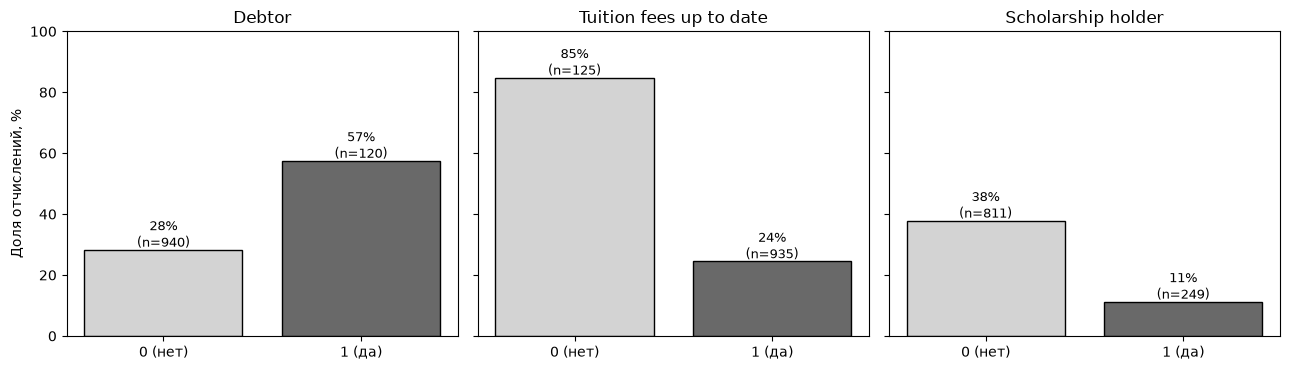

In [13]:
fin = ["Debtor", "Tuition fees up to date", "Scholarship holder"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a, col in zip(axes, fin):
    g = explore.groupby(col)["Dropout"].agg(["mean", "size"])
    bars = a.bar(["0 (нет)", "1 (да)"], g["mean"] * 100, color=["lightgray", "dimgray"], edgecolor="black")
    for b, (m, n) in zip(bars, g.itertuples(index=False)):
        a.text(b.get_x() + b.get_width()/2, b.get_height() + 1, f"{m*100:.0f}%\n(n={n})", ha="center", fontsize=9)
    a.set_title(col); a.set_ylim(0, 100)
axes[0].set_ylabel("Доля отчислений, %")
plt.tight_layout(); plt.show()

Над столбиками подписал размер группы (n), потому что доля по маленькой группе менее надёжна. Все три признака связаны с отчислением, сильнее всего оплата: из тех, кто не платит вовремя, отчислены почти все.

## 5. Гипотезы

**Гипотеза 1.** Должники отчисляются чаще.

Почему так думаю: часто отчисляют не за учёбу, а из-за денег. Если есть долг, студента могут отчислить или он сам уйдёт работать. На 25% это видно: среди должников отчислено около 60%, среди остальных около 28%.

Как проверяю: сравниваю долю отчисленных у должников и не должников, критерий хи-квадрат.

**Гипотеза 2.** Те, кто поступил в 23 года и старше, отчисляются чаще.

Почему так думаю: на графике 1 у отчисленных возраст больше (медиана 24 против 19 у выпускников). Взрослым сложнее совмещать учёбу с работой и семьёй. Порог 23 взял по графику, после него отчисленных становится больше, чем выпускников.

Как проверяю: доля отчисленных в двух группах (до 23 и 23+), хи-квадрат.

**Гипотеза 3.** У отчисленных ниже балл за 1 семестр, и среди них чаще встречаются те, кто не сдал ни одного предмета.

Почему так думаю: на boxplot у отчисленных медиана ниже и ящик доходит до нуля. Если первый семестр провален, студент скорее всего уйдёт. Это полезно знать, потому что оценки за 1 семестр известны рано.

Как проверяю: медианы балла сравниваю критерием Манна-Уитни (распределение не нормальное из-за нулей), долю студентов с 0 сданных - хи-квадрат.

**Гипотеза 4.** Вечерники отчисляются чаще только потому, что они старше.

Почему так думаю: на 25% вечерники отчисляются чаще дневных. Но вечерники в основном взрослые, а взрослые и так чаще уходят (гипотеза 2). Похоже на парадокс Симпсона из лекции.

Как проверяю: сравниваю вечерних и дневных отдельно внутри возрастных групп (до 23 и 23+). Если гипотеза верна, разница уменьшится или пропадёт.

## 6. Проверка гипотез на остальных 75%

Для каждой гипотезы вывожу доли, размеры групп и p-value. Если p-value меньше 0.05, разница значимая.

In [14]:
def share_table(data, group_col, labels=None):
    """Доля отчислений и размер каждой группы + критерий хи-квадрат независимости."""
    ct = pd.crosstab(data[group_col], data["Dropout"])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    out = data.groupby(group_col)["Dropout"].agg(доля_отчислений=lambda s: round(s.mean()*100, 1), n="size")
    if labels: out.index = labels
    print(f"χ² = {chi2:.1f}, p-value = {p:.2e}")
    return out

### Гипотеза 1: должники отчисляются чаще

In [15]:
share_table(holdout, "Debtor", ["без долга", "должник"])

χ² = 178.5, p-value = 1.04e-40


,доля_отчислений,n
без долга,27.7,2824
должник,62.7,357


Подтвердилась. Среди должников отчислено 62.7%, среди остальных 27.7%, больше чем в 2 раза. p-value намного меньше 0.05. Должников 357, так что группа не маленькая.

### Гипотеза 2: поступившие в 23+ отчисляются чаще

In [16]:
holdout = holdout.copy()
holdout["age_group"] = np.where(holdout["Age at enrollment"] >= 23, "23 и старше", "до 23")
share_table(holdout, "age_group")

χ² = 285.2, p-value = 5.65e-64


,доля_отчислений,n
age_group,,
23 и старше,51.9,1026
до 23,22.0,2155


Подтвердилась. Из тех, кто поступил в 23 и старше, отчислено 51.9%, из младших 22%. Но это связь, а не причина: возраст может просто значить, что человек работает или у него семья.

### Гипотеза 3: у отчисленных ниже балл и чаще 0 сданных предметов

In [17]:
g = "Curricular units 1st sem (grade)"
drop = holdout.loc[holdout["Dropout"] == 1, g]
rest = holdout.loc[holdout["Dropout"] == 0, g]
u, p = stats.mannwhitneyu(drop, rest, alternative="less")
print(f"Медиана балла: отчисленные = {drop.median():.2f} (n={len(drop)}), остальные = {rest.median():.2f} (n={len(rest)})")
print(f"Среднее балла:  отчисленные = {drop.mean():.2f}, остальные = {rest.mean():.2f}")
print(f"Критерий Манна–Уитни (односторонний): p-value = {p:.2e}\n")

holdout["zero_approved_1st"] = (holdout["Curricular units 1st sem (approved)"] == 0).astype(int)
ct = pd.crosstab(holdout["Dropout"], holdout["zero_approved_1st"], normalize="index") * 100
ct.index = ["не отчислен", "отчислен"]; ct.columns = ["сдал ≥1 дисциплину, %", "0 сданных, %"]
chi2, p2, _, _ = stats.chi2_contingency(pd.crosstab(holdout["Dropout"], holdout["zero_approved_1st"]))
print(f"χ² для доли «0 сданных»: p-value = {p2:.2e}")
ct.round(1)

Медиана балла: отчисленные = 11.00 (n=1006), остальные = 12.80 (n=2175)
Среднее балла:  отчисленные = 7.64, остальные = 12.69
Критерий Манна–Уитни (односторонний): p-value = 5.65e-150

χ² для доли «0 сданных»: p-value = 3.07e-169


,"сдал ≥1 дисциплину, %","0 сданных, %"
не отчислен,98.4,1.6
отчислен,63.1,36.9


Подтвердилась. Медиана балла у отчисленных 11, у остальных 12.8. Но главное отличие в другом: 36.9% отчисленных не сдали в 1 семестре ни одного предмета, а среди остальных таких всего 1.6%.

Ещё тут видно, почему важно смотреть медиану: среднее у отчисленных 7.64, а медиана 11. Если смотреть только на среднее, кажется, что отчисленные учатся на 7 баллов. На самом деле одни учились нормально, а другие не сдали ничего.

### Гипотеза 4: вечерники отчисляются чаще из-за возраста?

In [18]:
holdout["attendance"] = holdout["Daytime/evening attendance"].map({1: "дневная", 0: "вечерняя"})

print("Без учёта возраста:")
print(holdout.groupby("attendance")["Dropout"].agg(доля=lambda s: round(s.mean()*100, 1), n="size"), "\n")

print("Внутри возрастных групп:")
inside = holdout.groupby(["age_group", "attendance"])["Dropout"].agg(доля=lambda s: round(s.mean()*100, 1), n="size")
inside

Без учёта возраста:
            доля     n
attendance            
вечерняя    43.1   362
дневная     30.2  2819 

Внутри возрастных групп:


доля     n
age_group   attendance            
23 и старше вечерняя    45.3   329
            дневная     54.9   697
до 23       вечерняя    21.2    33
            дневная     22.0  2122

Подтвердилась. Если не учитывать возраст, вечерники отчисляются чаще (43.1% против 30.2%). Но внутри возрастных групп всё по-другому: до 23 лет доли почти одинаковые (21.2% и 22%), а среди 23+ вечерники отчисляются даже реже (45.3% против 54.9%). Это и есть парадокс Симпсона. Почти все вечерники взрослые (329 из 362), а взрослые чаще отчисляются в любом случае. Молодых вечерников всего 33, поэтому по ним вывод неточный.

## 7. Вывод

Очистка. Дубликатов и пропусков нет, но нашлось 183 строки с логическими ошибками (4%): 180 студентов без единого предмета за оба семестра (из них 75 выпускников) и 3 строки, где предметов без оценки больше, чем записано. Удалил их по одному правилу для всех классов.

Гипотезы. Все 4 гипотезы, которые я придумал на 25% данных, подтвердились на остальных 75%:
1. Должники отчисляются в 2 с лишним раза чаще.
2. Поступившие в 23+ отчисляются примерно в 2 раза чаще.
3. У отчисленных ниже балл за 1 семестр, и треть из них не сдала ни одного предмета.
4. Вечерники отчисляются чаще только из-за возраста: внутри возрастных групп разницы нет или она обратная.

Для модели самые полезные признаки: деньги (долг, оплата, стипендия), оценки за 1 семестр и возраст. Форму обучения без учёта возраста использовать нельзя. Признаки 2 семестра для ранней модели лучше убрать, потому что в начале учёбы их ещё нет.

Ограничения: это связи, а не причины. Данные только одного вуза, курс 2 после очистки почти пропал (35 студентов), а в классе "не отчислен" есть Enrolled, которые ещё могут отчислиться.